In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import statistics
import Funcs as fn
import seaborn as sns
from matplotlib.patches import Patch
from scipy.stats import kruskal

from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import KNNImputer, SimpleImputer, IterativeImputer

#Data Balancing
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from imblearn.ensemble import BalancedBaggingClassifier
from sklearn.metrics import accuracy_score, classification_report

In [3]:
df_mice = pd.read_csv("ImputedData.csv")

df_knn = pd.read_csv("KNN_ImputedData.csv")

df = pd.read_excel('CleanedFile.xlsx')

df1 = pd.read_excel("CDC_CleanedFile.xlsx")

df2 = pd.read_csv("ComparisonImpute.csv")

# Imputation

In [4]:
# MICE Style Approach

# use fn to remove numerical values, and columns with >70% NaN
numdf = fn.structure_missing_values_numeric(df)

# get numeric columns
num_col = numdf.columns

# Create Iterative Imputer
imp = IterativeImputer(max_iter=20, random_state=0)

# Impute missing numeric values
numdf[num_col] = imp.fit_transform(numdf[num_col])

#use fn to remove categorical values, and columns with >70% NaN
catdf = fn.structure_missing_values_categorical(df)

# get cat. columns
cat_col = catdf.select_dtypes(include="object").columns

# Create Simple Imputer
imp = SimpleImputer(strategy='most_frequent')

# Impute missing categorical values
catdf[cat_col] = imp.fit_transform(catdf[cat_col])

# COMBINE NUMERIC + CATEGORICAL
df_imputed = pd.concat([numdf, catdf], axis=1)

# Save
df_imputed.to_csv("ImputedData.csv", index=False)


In [5]:
# KNN Approach

# Get usable numeric data
numdf = fn.structure_missing_values_numeric(df)

# Get numeric columns
num_col = numdf.columns

# Create KNN Imputer
knn_imp = KNNImputer(n_neighbors=5)

# Impute missing numeric values
numdf[num_col] = knn_imp.fit_transform(numdf[num_col])

# Get usable categorical data
catdf = fn.structure_missing_values_categorical(df)

# Get categorical columns
cat_col = catdf.select_dtypes(include="object").columns

# Create categorical imputer
cat_imp = SimpleImputer(strategy="most_frequent")

# Impute missing categorical values
catdf[cat_col] = cat_imp.fit_transform(catdf[cat_col])

# combine both df
df_knn = pd.concat([numdf, catdf], axis=1)

# Save
df_knn.to_csv("KNN_ImputedData.csv", index=False)



# Graphs

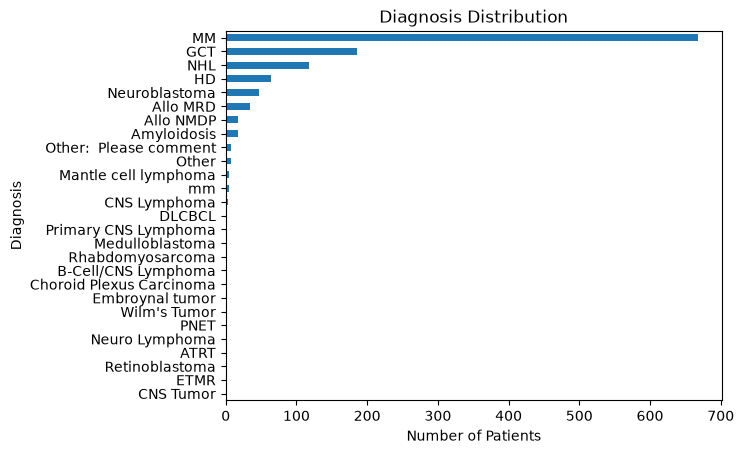

In [6]:
# 1. Graph a diagnosis distribution MICE

# select a column
diagnosis = df_mice["Diagnosis"]

# count each diagnosis
diagnosis_counts = diagnosis.value_counts()

# make the graph
ax = diagnosis_counts.plot(kind="barh")

# put most common diagnosis on the top
ax.invert_yaxis()

# Customize
plt.xlabel("Number of Patients")
plt.ylabel("Diagnosis")
plt.title("Diagnosis Distribution")

#save
plt.savefig("Diagnosis Distribution_MICE.png", bbox_inches="tight")

# show
plt.show()


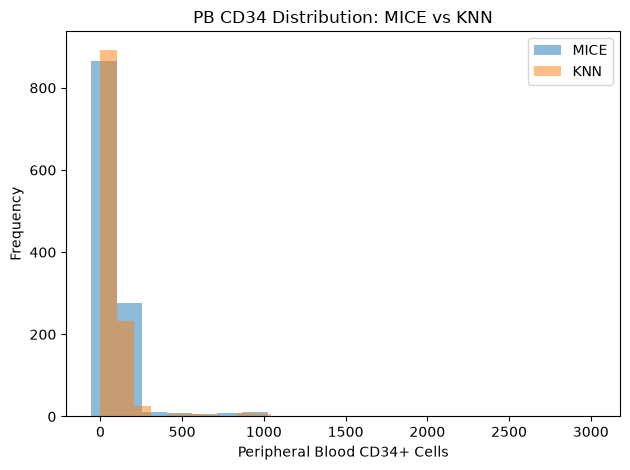

In [7]:
# Compare PD CD34 distributions between KNN and MICE

column = "Peripheral Blood CD34+ Cells"

df_mice[column].plot(
    kind="hist",
    bins=20,
    alpha=0.5, # makes semi transparent for overlap visualization
    label="MICE"
)

df_knn[column].plot(
    kind="hist",
    bins=20,
    alpha=0.5, 
    label="KNN"
)

plt.xlabel("Peripheral Blood CD34+ Cells")
plt.ylabel("Frequency")
plt.title("PB CD34 Distribution: MICE vs KNN")
plt.legend()
plt.tight_layout()
plt.show()

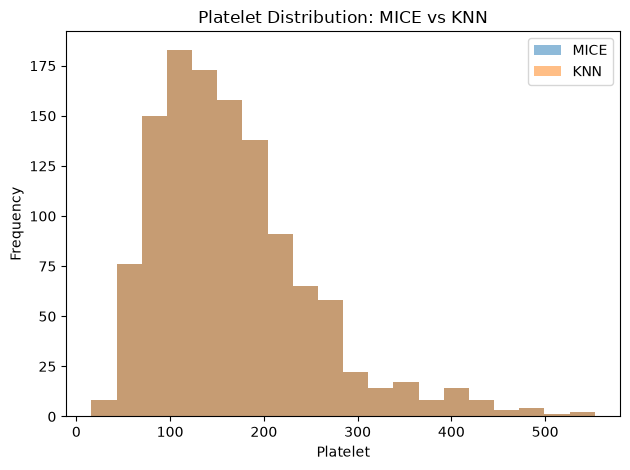

In [8]:
# Compare platelet dist. between knn and mice

column = "Platelet"

df_mice[column].plot(
    kind="hist",
    bins=20,
    alpha=0.5,
    label="MICE"
)

df_knn[column].plot(
    kind="hist",
    bins=20,
    alpha=0.5,
    label="KNN"
)

plt.xlabel("Platelet")
plt.ylabel("Frequency")
plt.title("Platelet Distribution: MICE vs KNN")
plt.legend()
plt.tight_layout()

plt.savefig("Platelet Distribution.png", bbox_inches="tight")

plt.show()

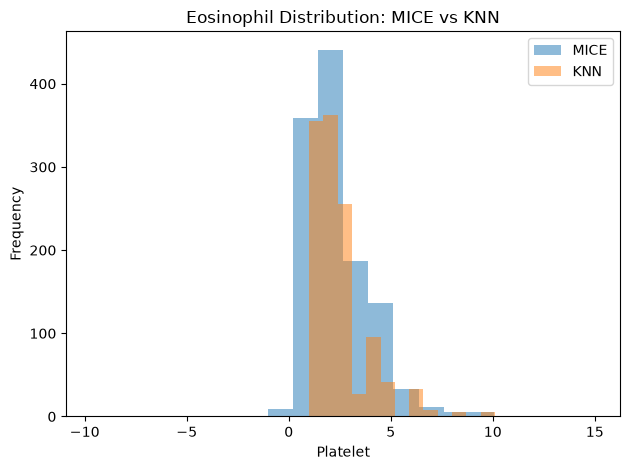

In [9]:
# Compare Hgb dist. between knn and mice

column = "Eosinophil"

df_mice[column].plot(
    kind="hist",
    bins=20,
    alpha=0.5,
    label="MICE"
)

df_knn[column].plot(
    kind="hist",
    bins=20,
    alpha=0.5,
    label="KNN"
)

plt.xlabel("Platelet")
plt.ylabel("Frequency")
plt.title("Eosinophil Distribution: MICE vs KNN")
plt.legend()
plt.tight_layout()

plt.savefig("Eosinophil Dist.png", bbox_inches="tight")

plt.show()

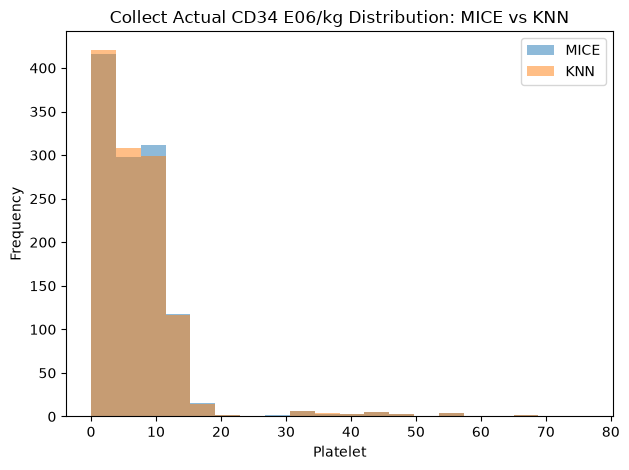

In [10]:
# Compare collected cd34/kg dist. between knn and mice

column = "Collect Actual CD34 E06/kg"

df_mice[column].plot(
    kind="hist",
    bins=20,
    alpha=0.5,
    label="MICE"
)

df_knn[column].plot(
    kind="hist",
    bins=20,
    alpha=0.5,
    label="KNN"
)

plt.xlabel("Platelet")
plt.ylabel("Frequency")
plt.title("Collect Actual CD34 E06/kg Distribution: MICE vs KNN")
plt.legend()
plt.tight_layout()

plt.savefig("cd34 dist.png", bbox_inches="tight")

plt.show()

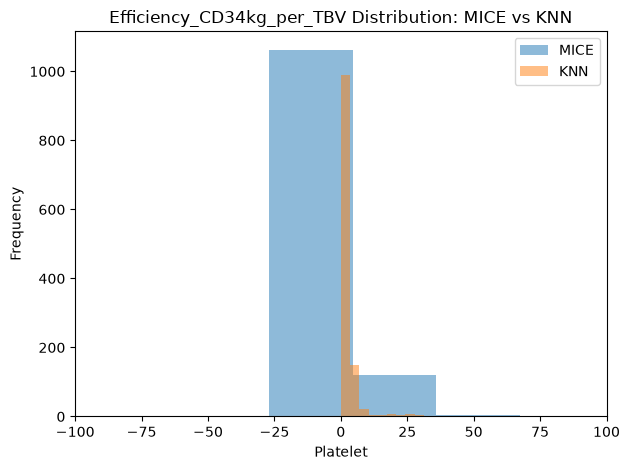

In [11]:
# compare efficiency to knn vs mice

column = "Efficiency_CD34kg_per_TBV"

df_mice[column].plot(
    kind="hist",
    bins=20,
    alpha=0.5,
    label="MICE"
)

df_knn[column].plot(
    kind="hist",
    bins=20,
    alpha=0.5,
    label="KNN"
)

plt.xlabel("Platelet")
plt.ylabel("Frequency")

plt.xlim(-100, 100)
plt.title("Efficiency_CD34kg_per_TBV Distribution: MICE vs KNN")
plt.legend()
plt.tight_layout()

plt.savefig("efficiency dist.png", bbox_inches="tight")

plt.show()

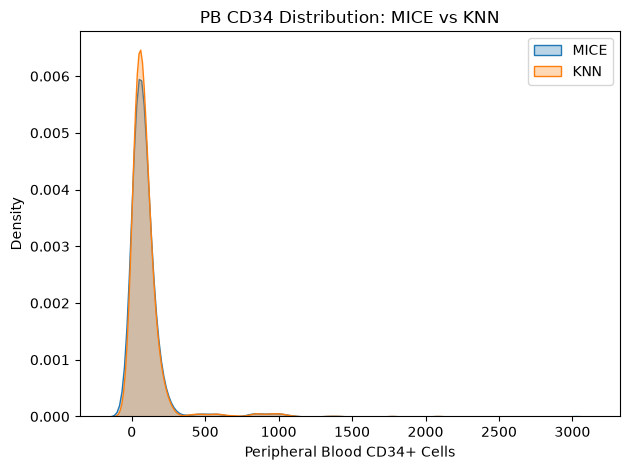

In [12]:
# making a kde chart

column = "Peripheral Blood CD34+ Cells"

# KDE for MICE
sns.kdeplot(
    data=df_mice,
    x=column,
    label="MICE",
    fill=True,
    alpha=0.3
)

# KDE for KNN
sns.kdeplot(
    data=df_knn,
    x=column,
    label="KNN",
    fill=True,
    alpha=0.3
)

# Customize
plt.xlabel("Peripheral Blood CD34+ Cells")
plt.ylabel("Density")
plt.title("PB CD34 Distribution: MICE vs KNN")
plt.legend()
plt.tight_layout()

# Save
plt.savefig(
    "PB_CD34_KDE_MICE_vs_KNN.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

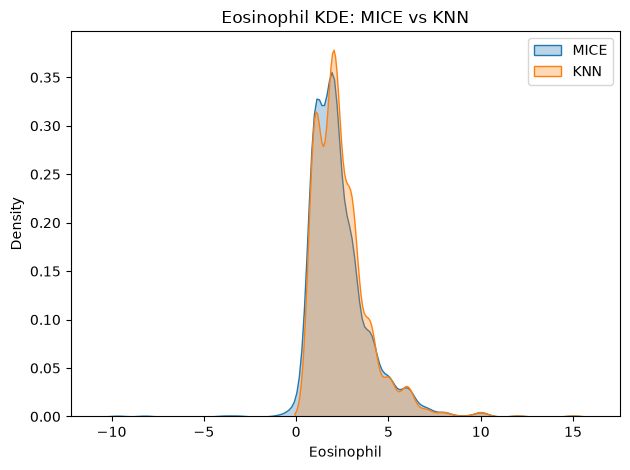

In [13]:
# making a kde chart

column = "Eosinophil"

# KDE for MICE
sns.kdeplot(
    data=df_mice,
    x=column,
    label="MICE",
    fill=True,
    alpha=0.3
)

# KDE for KNN
sns.kdeplot(
    data=df_knn,
    x=column,
    label="KNN",
    fill=True,
    alpha=0.3
)

# Customize
plt.xlabel("Eosinophil")
plt.ylabel("Density")
plt.title("Eosinophil KDE: MICE vs KNN")
plt.legend()
plt.tight_layout()

# Save
plt.savefig(
    "eosinophil kde.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

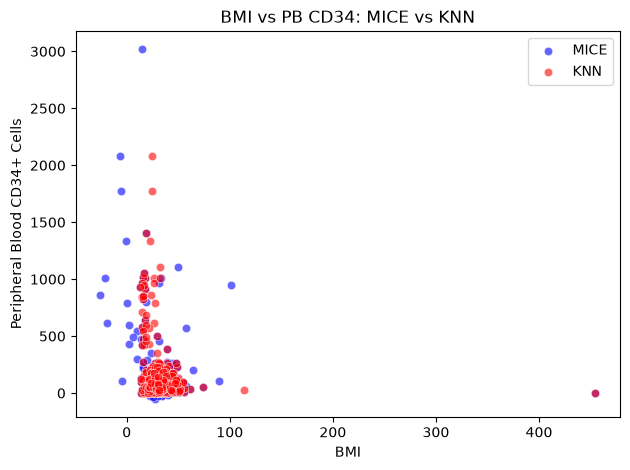

In [14]:
# make a scatterplot

x = "BMI"
y = "Peripheral Blood CD34+ Cells"

# MICE
sns.scatterplot(
    data=df_mice,
    x=x,
    y=y,
    label="MICE",
    color="blue",
    alpha=0.6
)

# KNN
sns.scatterplot(
    data=df_knn,
    x=x,
    y=y,
    label="KNN",
    color="red",
    alpha=0.6
)

plt.xlabel("BMI")
plt.ylabel("Peripheral Blood CD34+ Cells")
plt.title("BMI vs PB CD34: MICE vs KNN")

plt.legend()
plt.tight_layout()
plt.savefig("BMI vs PB CD34.png")
plt.show()

In [15]:
dfnum = df.select_dtypes(include='number')

dfcat = df.select_dtypes(include='object')

In [16]:
# Columns to exclude from the graph
exclude = [
    "Survival Days",
    "Vital Status_Code",
    "Collect Actual CD34 E06/kg",
    "Abs Neutrophil",
    "Abs Lymphocytes",
    "Abs Monocyte",
    "Abs Eosinophil",
    "Abs Basophil",
    "Abs Band",
    "Abs Metamyelocyte",
    "Abs Myelocyte",
    "Abs Promyelocyte",
    "Abs Blast",
    "Abs Plasma Cell",
    "Abs Other Cells Bld",
    "Neu#",
    "Lym#",
    "Mono#",
    "Eos#",
    "Baso#"
]

# Columns to review for redundancy
duplicates = ["BMI"]

# Find columns with 30% or more missing values
remove = df.columns[df.isna().mean() >= 0.30].tolist()

# Combine exclusion lists
exclude = exclude + remove

NaN_co = (df.isna().sum() > 1) & (df.isna().sum() >= 1193)

# Remove excluded columns and sort
NaN_col = NaN_co.drop(index=exclude, errors="ignore")
NaN_col = NaN_col.sort_values(ascending=True)

# Assign colors
colors = []

for col in NaN_col.index:
    if col in duplicates:
        colors.append("orange")
    else:
        colors.append("steelblue")

# Create graph
ax = NaN_col.plot(kind="barh", color=colors, figsize=(12, 15))

# Add missing-value counts
ax.bar_label(ax.containers[0], padding=3, fontsize=8)

# Adjust label sizes
ax.tick_params(axis="y", labelsize=8)
ax.tick_params(axis="x", labelsize=10)

# Highlight labels when a variable has 0 missing values
for label, col in zip(ax.get_yticklabels(), NaN_col.index):
    if NaN_col[col] == 0:
        if col in duplicates:
            label.set_color("darkorange")
        else:
            label.set_color("steelblue")

        label.set_fontweight("bold")

# Customize
plt.xlabel("Number of Missing Values")
plt.ylabel("Variables")
plt.title("Missing Data Distribution (<30% Missingness)")

# Legend
key = [
    Patch(color="orange", label="Review for Redundancy"),
    Patch(color="steelblue", label="Retain")
]

ax.legend(handles=key, loc="lower right", fontsize=9)

# Leave space for numerical labels
ax.set_xlim(0, max(NaN_col.max() * 1.15, 1))

# Fix spacing
plt.tight_layout()

# Save before showing
plt.savefig("NaN_Distribution.png", dpi=300, bbox_inches="tight")

plt.show()

# Print removed columns
print("Excluded columns:")
for col in dict.fromkeys(exclude):
    print(col)

TypeError: no numeric data to plot

In [ ]:

NaN_co2 = dfcat.isna().sum()[(dfcat.isna().sum() > 1) & (dfcat.isna().sum() <= 1193)]

NaN_col2 = NaN_co2.sort_values(ascending=True)

# Make the graph taller
ax = NaN_col2.plot(kind="barh", figsize=(12, 4))
ax.bar_label(ax.containers[0], padding=3, fontsize=8)
# Adjust label sizes
ax.tick_params(axis="y", labelsize=8)
ax.tick_params(axis="x", labelsize=10)

# Customize
plt.xlabel("Number of Missing Values")
plt.ylabel("Variables")
plt.title("Categorical Missing Data Distribution")

# Fix spacing
plt.tight_layout()

# Save
plt.savefig("NaN cat Distribution.png", dpi=300, bbox_inches="tight")

plt.show()

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# -------------------------------------------------
# 1. VARIABLES TO EXCLUDE FROM MODEL TRAINING
# -------------------------------------------------

exclude_training = [
    "Demo key", "DOB",
    "Outcome_Binary", "Outcome_Binary2", "Outcome_Binary3",
    "Outcome_Binary PB", "PB Cutoff",
    "Collect Actual CD34 E06/kg",
    "% MNC Product", "Efficiency_CD34kg_per_TBV",
    "Liters of WBP", "Total Blood Volumes",
    "Vital Status", "Vital Status_Code",
    "Survival Days", "Date of Death", "Cause of Death",
    "Most Recent Encounter",
    "Survived\n30 Days", "Survived\n100 Days",
    "Survived\n1 Year", "Survived\n5 Years",
    "Complication", "Complication Status",
    "Transplant Date", "GVHD Prophylaxis"
]

# -------------------------------------------------
# 2. VARIABLES TO REVIEW FOR REDUNDANCY
# -------------------------------------------------

review_duplicates = [
    "Sex", "Binary Sex",
    "Wt", "Recipient Weight kg", "Ht", "BMI",
    "Neutrophil", "Neutrophils %", "Abs Neutrophil", "Neu#",
    "Lymphocyte", "Lymphocytes %", "Abs Lymphocytes", "Lym#",
    "Monocyte", "Monocytes %", "Abs Monocyte", "Mono#",
    "Eosinophil", "Eosinophils %", "Abs Eosinophil", "Eos#",
    "Basophil", "Basophils %", "Abs Basophil", "Baso#",
    "Estimated GFR (CKD-EPI)",
    "Estimated GFR (CKD-EPI, no race)",
    "Estimated CRCL (CG)",
    "PT", "INR",
    "Mobilization", "Mobilization type",
    "Mobilization type (Excluding 0's",
    "Mobilzation type (5.0)",
    "Peripheral Blood CD34+ Cells",
    "Pre PB CD34+ cells/cumm (only record on 1st day)"
]

# -------------------------------------------------
# 3. COLORS AND CLASSIFICATION
# -------------------------------------------------

colors = {
    "Exclude from Training": "#B85C5C",
    "Review for Redundancy": "#C59643",
    "Remove: >=70% Missing": "#8B9199",
    "Retain / Review": "#448C85"
}

cutoff = 70

def classify_variable(column, missing_pct):
    # Training exclusions take priority so they remain visible
    if column in exclude_training:
        return "Exclude from Training"

    # High missingness takes priority over redundancy review
    if missing_pct >= cutoff:
        return "Remove: >=70% Missing"

    if column in review_duplicates:
        return "Review for Redundancy"

    return "Retain / Review"


# -------------------------------------------------
# 4. FUNCTION TO PLOT EITHER DATA TYPE
# -------------------------------------------------

def plot_missingness(columns, title, filename):

    missing = df[columns].isna().sum()

    plot_df = pd.DataFrame({
        "Missing": missing,
        "Missing %": df[columns].isna().mean() * 100
    })

    plot_df["Group"] = [
        classify_variable(col, plot_df.loc[col, "Missing %"])
        for col in plot_df.index
    ]

    # Sort by missing count, largest at the top
    plot_df = plot_df.sort_values("Missing", ascending=True)

    fig_height = max(6, len(plot_df) * 0.25)

    fig, ax = plt.subplots(figsize=(14, fig_height))

    ax.barh(
        plot_df.index,
        plot_df["Missing"],
        color=plot_df["Group"].map(colors)
    )

    # Numbers at the ends of the bars
    ax.bar_label(ax.containers[0], padding=3, fontsize=8)

    # 70% cutoff
    ax.axvline(
        len(df) * 0.70,
        color="black",
        linestyle="--",
        linewidth=1.3
    )

    ax.set_title(title, fontsize=14)
    ax.set_xlabel("Number of Missing Values")
    ax.set_ylabel("")
    ax.tick_params(axis="y", labelsize=8)

    ax.set_xlim(0, len(df) * 1.12)

    # Minimal legend
    legend_items = [
        Patch(facecolor=color, label=group)
        for group, color in colors.items()
    ]

    legend_items.append(
        plt.Line2D(
            [0], [0],
            color="black",
            linestyle="--",
            label="70% Missingness Cutoff"
        )
    )

    ax.legend(
        handles=legend_items,
        loc="lower right",
        fontsize=9,
        frameon=False
    )

    # No distracting grid lines
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    plt.tight_layout()
    plt.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()


# -------------------------------------------------
# 5. SEPARATE NUMERICAL AND CATEGORICAL GRAPHS
# -------------------------------------------------

numeric_cols = df.select_dtypes(include="number").columns
categorical_cols = df.select_dtypes(exclude="number").columns

plot_missingness(
    numeric_cols,
    "Numerical Missing Data and Proposed Variable Exclusions",
    "Numerical_Missingness_Grouped.png"
)

plot_missingness(
    categorical_cols,
    "Categorical Missing Data and Proposed Variable Exclusions",
    "Categorical_Missingness_Grouped.png"
)

In [ ]:
# graph BMI and abs eosinophil, diff between abs e. and e., 

In [ ]:
column = "Monocyte"

df_mice[column].plot(
    kind="hist",
    bins=20,
    alpha=0.5,
    label="MICE"
)

df_knn[column].plot(
    kind="hist",
    bins=20,
    alpha=0.5,
    label="KNN"
)

plt.xlabel("Platelet")
plt.ylabel("Frequency")
plt.title("Monocyte Distribution: MICE vs KNN")
plt.legend()
plt.tight_layout()

plt.savefig("Monocyte Histogram.png", bbox_inches="tight")

plt.show()

In [ ]:
column = "Lymphocyte"

df_mice[column].plot(
    kind="hist",
    bins=20,
    alpha=0.5,
    label="MICE"
)

df_knn[column].plot(
    kind="hist",
    bins=20,
    alpha=0.5,
    label="KNN"
)

plt.xlabel("Platelet")
plt.ylabel("Frequency")
plt.title("Lymphocyte Distribution: MICE vs KNN")
plt.legend()
plt.tight_layout()

plt.savefig("Lymphocyte Histogram.png", bbox_inches="tight")

plt.show()

In [ ]:
df["Lymphocyte"].isna().sum()

In [ ]:
column = "Ht"

df_mice[column].plot(
    kind="hist",
    bins=20,
    alpha=0.5,
    label="MICE"
)

df_knn[column].plot(
    kind="hist",
    bins=20,
    alpha=0.5,
    label="KNN"
)

plt.xlabel("Height")
plt.ylabel("Frequency")
plt.title("Height Distribution: MICE vs KNN")
plt.legend()
plt.tight_layout()

plt.savefig("Ht Histogram.png", bbox_inches="tight")

plt.show()

In [ ]:
df["BMI"].isna().sum()

# 13 Bar Graphs

In [ ]:
# dictionary
clinical_groups = {
    "1. Demographics": [
        "Demo key", "DOB", "Age", "Sex", "Binary Sex",
        "Race", "Ethnicity"
    ],

    "2. Body Measurements": [
        "Ht", "Wt", "Recipient Weight kg", "BMI"
    ],

    "3. Complete Blood Count": [
        "WBC", "RBC", "Hgb", "Hct", "Platelet",
        "MCV", "MCH", "MCHC", "RDW", "MPV"
    ],

    "4. WBC Differential": [
        "Neutrophil", "Neutrophils %", "Abs Neutrophil", "Neu#",
        "Lymphocyte", "Lymphocytes %", "Abs Lymphocytes", "Lym#",
        "Reactive Lymph",
        "Monocyte", "Monocytes %", "Abs Monocyte", "Mono#",
        "Eosinophil", "Eosinophils %", "Abs Eosinophil", "Eos#",
        "Basophil", "Basophils %", "Abs Basophil", "Baso#"
    ],

    "5. Immature and Abnormal Blood Cells": [
        "Band", "Abs Band",
        "Metamyelo", "Abs Metamyelocyte",
        "Myelocyte", "Abs Myelocyte",
        "Promyelocyte", "Abs Promyelocyte",
        "Blast", "Abs Blast",
        "Plasma Cell", "Abs Plasma Cell",
        "Other Cells Bld", "Abs Other Cells Bld",
        "No. of Nuc RBC", "# Cells Counted"
    ],

    "6. Kidney Function and Electrolytes": [
        "BUN SerPl QN", "Creatinine SerPl QN",
        "Estimated CRCL (CG)",
        "Estimated GFR (CKD-EPI)",
        "Estimated GFR (CKD-EPI, no race)",
        "Sodium SerPl QN", "Potassium SerPl QN",
        "Chloride SerPl QN", "CO2 SerPl QN",
        "Calcium Total SerPl QN",
        "Magnesium SerPl QN", "Phosphorus SerPl QN",
        "Anion Gap", "Lab Glucose", "Uric Acid SerPl QN"
    ],

    "7. Liver Function and Proteins": [
        "Albumin SerPl QN", "Alkaline Phos SerPl QN",
        "ALT SerPl QN", "AST SerPl QN",
        "Bilirubin Total SerPl QN",
        "Total Protein SerPl QN", "LD SerPl QN"
    ],

    "8. Immunoglobulins and Light Chains": [
        "IgA Ser QN", "IgG Ser QN", "IgM Ser QN",
        "Free Kappa L.C. Ser QN",
        "Free Kappa/Lambda Ratio"
    ],

    "9. Coagulation": [
        "PT", "INR", "aPTT"
    ],

    "10. Stem Cell Mobilization and Collection": [
        "Mobilization", "Mobilization type",
        "Mobilization type (Excluding 0's",
        "Mobilzation type (5.0)",
        "Peripheral Blood CD34+ Cells",
        "Pre PB CD34+ cells/cumm (only record on 1st day)",
        "Collect Actual CD34 E06/kg",
        "% MNC Product",
        "Liters of WBP", "Total Blood Volumes",
        "Efficiency_CD34kg_per_TBV",
        "Outcome_Binary", "Outcome_Binary2",
        "Outcome_Binary3", "PB Cutoff",
        "Outcome_Binary PB"
    ],

    "11. Disease and Clinical Status": [
        "Diagnosis", "KPS", "Comorbidity Index"
    ],

    "12. Transplant and Complications": [
        "Transplant Date", "IndexDate",
        "Preparative Regimen", "GVHD Prophylaxis",
        "Complication", "Complication Status"
    ],

    "13. Survival and Follow-Up": [
        "Vital Status", "Vital Status_Code",
        "Date of Death", "Cause of Death",
        "Most Recent Encounter", "Survival Days",
        "Survived\n30 Days", "Survived\n100 Days",
        "Survived\n1 Year", "Survived\n5 Years"
    ]
}


In [ ]:
# "1. Demographics"

NaN_co = df[clinical_groups["1. Demographics"]].isna().sum()

exclude = ["Demo key", "DOB", "Binary Sex"]
duplicates = ["Ethnicity","Race"]


# Assign colors
colors = []


NaN_col = NaN_co.sort_values(ascending=True)
NaN_col = NaN_col.drop(index=exclude, errors="ignore")

for col in NaN_col.index:
    if col in duplicates:
        colors.append("orange")
    elif df[col].isna().mean() >= 0.30:
        colors.append("gray")
    else:
        colors.append("steelblue")
    


# Make the graph taller
ax = NaN_col.plot(kind="barh", color=colors, figsize=(6, 3))
ax.bar_label(ax.containers[0], padding=3, fontsize=8)

for label, col in zip(ax.get_yticklabels(), NaN_col.index):
    if NaN_col[col] == 0:
        if col in duplicates:
            label.set_color("darkorange")
        else:
            label.set_color("steelblue")

        label.set_fontweight("bold")

# Adjust label sizes
ax.tick_params(axis="y", labelsize=8)
ax.tick_params(axis="x", labelsize=10)



# Customize
plt.xlabel("Number of Missing Values")
plt.ylabel("Variables")
plt.title("Demographics")

key = [
    
    Patch(color="orange", label="Review"),
    Patch(color="gray", label="≥30% Missing"),
    Patch(color="steelblue", label="Retain")
]

# add threshold line
threshold = len(df) * .30

ax.axvline(threshold, color="black", linestyle="--", linewidth=1, label="30% Threshold")

ax.legend(handles=key + [plt.Line2D([0], [0], color="black", linestyle="--", label="30% Threshold")], loc="lower right", fontsize=9)


# Fix spacing
plt.tight_layout()

# Save
plt.savefig("1. Demographics.png", dpi=300, bbox_inches="tight")

plt.show()



In [ ]:
# "2. Body Measurements"

NaN_co = df[clinical_groups["2. Body Measurements"]].isna().sum()

exclude = ["Recipient Weight kg", "BMI"]
duplicates = []


# Assign colors
colors = []


NaN_col = NaN_co.sort_values(ascending=True)
NaN_col = NaN_col.drop(index=exclude, errors="ignore")

for col in NaN_col.index:
    if col in duplicates:
        colors.append("orange")
    elif df[col].isna().mean() >= 0.30:
        colors.append("gray")
    else:
        colors.append("steelblue")
    


# Make the graph taller
ax = NaN_col.plot(kind="barh", color=colors, figsize=(6, 3))
ax.bar_label(ax.containers[0], padding=3, fontsize=8)

for label, col in zip(ax.get_yticklabels(), NaN_col.index):
    if NaN_col[col] == 0:
        if col in duplicates:
            label.set_color("darkorange")
        else:
            label.set_color("steelblue")

        label.set_fontweight("bold")

# Adjust label sizes
ax.tick_params(axis="y", labelsize=8)
ax.tick_params(axis="x", labelsize=10)



# Customize
plt.xlabel("Number of Missing Values")
plt.ylabel("Variables")
plt.title("Body Measurements")

key = [
    
    Patch(color="orange", label="Review"),
    Patch(color="gray", label="≥30% Missing"),
    Patch(color="steelblue", label="Retain")
]

# add threshold line
threshold = len(df) * .30

ax.axvline(threshold, color="black", linestyle="--", linewidth=1, label="30% Threshold")

ax.legend(handles=key + [plt.Line2D([0], [0], color="black", linestyle="--", label="30% Threshold")], loc="lower right", fontsize=9)


# Fix spacing
plt.tight_layout()

# Save
plt.savefig("2. Body Measurements.png", dpi=300, bbox_inches="tight")

plt.show()


In [ ]:
# "3. Complete Blood Count"

NaN_co = df[clinical_groups["3. Complete Blood Count"]].isna().sum()

exclude = []
duplicates = ["MCV", "MCH", "MCHC"]
# could calculate using MCV = RBC and Hct, MCH = Hgb and RBC, MCHC = Hgb and Hct

# Assign colors
colors = []


NaN_col = NaN_co.sort_values(ascending=True)
NaN_col = NaN_col.drop(index=exclude, errors="ignore")

for col in NaN_col.index:
    if col in duplicates:
        colors.append("orange")
    elif df[col].isna().mean() >= 0.30:
        colors.append("gray")
    else:
        colors.append("steelblue")
    


# Make the graph taller
ax = NaN_col.plot(kind="barh", color=colors, figsize=(6, 3))
ax.bar_label(ax.containers[0], padding=3, fontsize=8)

for label, col in zip(ax.get_yticklabels(), NaN_col.index):
    if NaN_col[col] == 0:
        if col in duplicates:
            label.set_color("darkorange")
        else:
            label.set_color("steelblue")

        label.set_fontweight("bold")

# Adjust label sizes
ax.tick_params(axis="y", labelsize=8)
ax.tick_params(axis="x", labelsize=10)



# Customize
plt.xlabel("Number of Missing Values")
plt.ylabel("Variables")
plt.title("Complete Blood Count")

key = [
    
    Patch(color="orange", label="Review"),
    Patch(color="gray", label="≥30% Missing"),
    Patch(color="steelblue", label="Retain")
]

# add threshold line
threshold = len(df) * .30

ax.axvline(threshold, color="black", linestyle="--", linewidth=1, label="30% Threshold")

ax.legend(handles=key + [plt.Line2D([0], [0], color="black", linestyle="--", label="30% Threshold")], loc="lower right", fontsize=9)


# Fix spacing
plt.tight_layout()

# Save
plt.savefig("Complete Blood Count", dpi=300, bbox_inches="tight")

plt.show()


In [ ]:
# "4. WBC Differential"

NaN_co = df[clinical_groups["4. WBC Differential"]].isna().sum()

exclude = []
duplicates = []


# Assign colors
colors = []


NaN_col = NaN_co.sort_values(ascending=True)
NaN_col = NaN_col.drop(index=exclude, errors="ignore")

for col in NaN_col.index:
    if col in duplicates:
        colors.append("orange")
    elif df[col].isna().mean() >= 0.30:
        colors.append("gray")
    else:
        colors.append("steelblue")
    


# Make the graph taller
ax = NaN_col.plot(kind="barh", color=colors, figsize=(12, 5))
ax.bar_label(ax.containers[0], padding=3, fontsize=8)

for label, col in zip(ax.get_yticklabels(), NaN_col.index):
    if NaN_col[col] == 0:
        if col in duplicates:
            label.set_color("darkorange")
        else:
            label.set_color("steelblue")

        label.set_fontweight("bold")

# Adjust label sizes
ax.tick_params(axis="y", labelsize=8)
ax.tick_params(axis="x", labelsize=10)



# Customize
plt.xlabel("Number of Missing Values")
plt.ylabel("Variables")
plt.title("WBC Differential")

key = [
    
    Patch(color="orange", label="Review"),
    Patch(color="gray", label="≥30% Missing"),
    Patch(color="steelblue", label="Retain")
]

# add threshold line
threshold = len(df) * .30

ax.axvline(threshold, color="black", linestyle="--", linewidth=1, label="30% Threshold")

ax.legend(handles=key + [plt.Line2D([0], [0], color="black", linestyle="--", label="30% Threshold")], loc="lower right", fontsize=9)


# Fix spacing
plt.tight_layout()

# Save
plt.savefig("WBC Differential", dpi=300, bbox_inches="tight")

plt.show()


In [ ]:
# "5. Immature and Abnormal Blood Cells"

NaN_co = df[clinical_groups["5. Immature and Abnormal Blood Cells"]].isna().sum()

exclude = []
duplicates = ["# Cells Counted"]


# Assign colors
colors = []


NaN_col = NaN_co.sort_values(ascending=True)
NaN_col = NaN_col.drop(index=exclude, errors="ignore")

for col in NaN_col.index:
    if col in duplicates:
        colors.append("orange")
    elif df[col].isna().mean() >= 0.30:
        colors.append("gray")
    else:
        colors.append("steelblue")
    


# Make the graph taller
ax = NaN_col.plot(kind="barh", color=colors, figsize=(12, 5))
ax.bar_label(ax.containers[0], padding=3, fontsize=8)

for label, col in zip(ax.get_yticklabels(), NaN_col.index):
    if NaN_col[col] == 0:
        if col in duplicates:
            label.set_color("darkorange")
        else:
            label.set_color("steelblue")

        label.set_fontweight("bold")

# Adjust label sizes
ax.tick_params(axis="y", labelsize=8)
ax.tick_params(axis="x", labelsize=10)



# Customize
plt.xlabel("Number of Missing Values")
plt.ylabel("Variables")
plt.title("Immature and Abnormal Blood Cells")

key = [
    
    Patch(color="orange", label="Review"),
    Patch(color="gray", label="≥30% Missing"),
    Patch(color="steelblue", label="Retain")
]

# add threshold line
threshold = len(df) * .30

ax.axvline(threshold, color="black", linestyle="--", linewidth=1, label="30% Threshold")

ax.legend(handles=key + [plt.Line2D([0], [0], color="black", linestyle="--", label="30% Threshold")], loc="lower right", fontsize=9)


# Fix spacing
plt.tight_layout()

# Save
plt.savefig("Immature and Abnormal Blood Cells", dpi=300, bbox_inches="tight")

plt.show()


In [ ]:
# "6. Kidney Function and Electrolytes"

NaN_co = df[clinical_groups["6. Kidney Function and Electrolytes"]].isna().sum()

exclude = []
duplicates = ["Anion Gap"]


# Assign colors
colors = []


NaN_col = NaN_co.sort_values(ascending=True)
NaN_col = NaN_col.drop(index=exclude, errors="ignore")

for col in NaN_col.index:
    if col in duplicates:
        colors.append("orange")
    elif df[col].isna().mean() >= 0.30:
        colors.append("gray")
    else:
        colors.append("steelblue")
    


# Make the graph taller
ax = NaN_col.plot(kind="barh", color=colors, figsize=(12, 5))
ax.bar_label(ax.containers[0], padding=3, fontsize=8)

for label, col in zip(ax.get_yticklabels(), NaN_col.index):
    if NaN_col[col] == 0:
        if col in duplicates:
            label.set_color("darkorange")
        else:
            label.set_color("steelblue")

        label.set_fontweight("bold")

# Adjust label sizes
ax.tick_params(axis="y", labelsize=8)
ax.tick_params(axis="x", labelsize=10)



# Customize
plt.xlabel("Number of Missing Values")
plt.ylabel("Variables")
plt.title("Kidney Function and Electrolytes")

key = [
    
    Patch(color="orange", label="Review"),
    Patch(color="gray", label="≥30% Missing"),
    Patch(color="steelblue", label="Retain")
]

# add threshold line
threshold = len(df) * .30

ax.axvline(threshold, color="black", linestyle="--", linewidth=1, label="30% Threshold")

ax.legend(handles=key + [plt.Line2D([0], [0], color="black", linestyle="--", label="30% Threshold")], loc="lower right", fontsize=9)


# Fix spacing
plt.tight_layout()

# Save
plt.savefig("Kidney Function and Electrolytes", dpi=300, bbox_inches="tight")

plt.show()

In [ ]:
# "7. Liver Function and Proteins"

NaN_co = df[clinical_groups["7. Liver Function and Proteins"]].isna().sum()

exclude = []
duplicates = ["Anion Gap"]


# Assign colors
colors = []


NaN_col = NaN_co.sort_values(ascending=True)
NaN_col = NaN_col.drop(index=exclude, errors="ignore")

for col in NaN_col.index:
    if col in duplicates:
        colors.append("orange")
    elif df[col].isna().mean() >= 0.30:
        colors.append("gray")
    else:
        colors.append("steelblue")
    


# Make the graph taller
ax = NaN_col.plot(kind="barh", color=colors, figsize=(8, 4))
ax.bar_label(ax.containers[0], padding=3, fontsize=8)

for label, col in zip(ax.get_yticklabels(), NaN_col.index):
    if NaN_col[col] == 0:
        if col in duplicates:
            label.set_color("darkorange")
        else:
            label.set_color("steelblue")

        label.set_fontweight("bold")

# Adjust label sizes
ax.tick_params(axis="y", labelsize=8)
ax.tick_params(axis="x", labelsize=10)



# Customize
plt.xlabel("Number of Missing Values")
plt.ylabel("Variables")
plt.title("Liver Function and Proteins")

key = [
    
    Patch(color="orange", label="Review"),
    Patch(color="gray", label="≥30% Missing"),
    Patch(color="steelblue", label="Retain")
]

# add threshold line
threshold = len(df) * .30

ax.axvline(threshold, color="black", linestyle="--", linewidth=1, label="30% Threshold")

ax.legend(handles=key + [plt.Line2D([0], [0], color="black", linestyle="--", label="30% Threshold")], loc="lower right", fontsize=9)


# Fix spacing
plt.tight_layout()

# Save
plt.savefig("Liver Function and Proteins", dpi=300, bbox_inches="tight")

plt.show()

In [ ]:
# "8. Immunoglobulins and Light Chains"

NaN_co = df[clinical_groups["8. Immunoglobulins and Light Chains"]].isna().sum()

exclude = []
duplicates = ["Anion Gap"]


# Assign colors
colors = []


NaN_col = NaN_co.sort_values(ascending=True)
NaN_col = NaN_col.drop(index=exclude, errors="ignore")

for col in NaN_col.index:
    if col in duplicates:
        colors.append("orange")
    elif df[col].isna().mean() >= 0.30:
        colors.append("gray")
    else:
        colors.append("steelblue")
    


# Make the graph taller
ax = NaN_col.plot(kind="barh", color=colors, figsize=(8, 4))
ax.bar_label(ax.containers[0], padding=3, fontsize=8)

for label, col in zip(ax.get_yticklabels(), NaN_col.index):
    if NaN_col[col] == 0:
        if col in duplicates:
            label.set_color("darkorange")
        else:
            label.set_color("steelblue")

        label.set_fontweight("bold")

# Adjust label sizes
ax.tick_params(axis="y", labelsize=8)
ax.tick_params(axis="x", labelsize=10)



# Customize
plt.xlabel("Number of Missing Values")
plt.ylabel("Variables")
plt.title("Immunoglobulins and Light Chains")

key = [
    
    Patch(color="orange", label="Review"),
    Patch(color="gray", label="≥30% Missing"),
    Patch(color="steelblue", label="Retain")
]

# add threshold line
threshold = len(df) * .30

ax.axvline(threshold, color="black", linestyle="--", linewidth=1, label="30% Threshold")

ax.legend(handles=key + [plt.Line2D([0], [0], color="black", linestyle="--", label="30% Threshold")], loc="lower right", fontsize=9)


# Fix spacing
plt.tight_layout()

# Save
plt.savefig("Immunoglobulins and Light Chains", dpi=300, bbox_inches="tight")

plt.show()

In [ ]:
# "9. Coagulation"

NaN_co = df[clinical_groups["9. Coagulation"]].isna().sum()

exclude = []
duplicates = ["Anion Gap"]


# Assign colors
colors = []


NaN_col = NaN_co.sort_values(ascending=True)
NaN_col = NaN_col.drop(index=exclude, errors="ignore")

for col in NaN_col.index:
    if col in duplicates:
        colors.append("orange")
    elif df[col].isna().mean() >= 0.30:
        colors.append("gray")
    else:
        colors.append("steelblue")
    


# Make the graph taller
ax = NaN_col.plot(kind="barh", color=colors, figsize=(8, 2))
ax.bar_label(ax.containers[0], padding=3, fontsize=8)

for label, col in zip(ax.get_yticklabels(), NaN_col.index):
    if NaN_col[col] == 0:
        if col in duplicates:
            label.set_color("darkorange")
        else:
            label.set_color("steelblue")

        label.set_fontweight("bold")

# Adjust label sizes
ax.tick_params(axis="y", labelsize=8)
ax.tick_params(axis="x", labelsize=10)



# Customize
plt.xlabel("Number of Missing Values")
plt.ylabel("Variables")
plt.title("Coagulation")

key = [
    
    Patch(color="orange", label="Review"),
    Patch(color="gray", label="≥30% Missing"),
    Patch(color="steelblue", label="Retain")
]

# add threshold line
threshold = len(df) * .30

ax.axvline(threshold, color="black", linestyle="--", linewidth=1, label="30% Threshold")




# Fix spacing
plt.tight_layout()

# Save
plt.savefig("Coagulation", dpi=300, bbox_inches="tight")

plt.show()

In [ ]:
# "10. Stem Cell Mobilization and Collection"

NaN_co = df[clinical_groups["10. Stem Cell Mobilization and Collection"]].isna().sum()

exclude = [ "Outcome_Binary",
	"Outcome_Binary2",
	"Outcome_Binary3",
	"Outcome_Binary PB",
    "Mobilization type (Excluding 0's",
    "Mobilzation type (5.0)", "PB Cutoff",
    "Mobilization type"]
training = [
    "Collect Actual CD34 E06/kg",
    "% MNC Product",
    "Liters of WBP",
    "Total Blood Volumes",
    "Efficiency_CD34kg_per_TBV",
   
]
review = [
      "Mobilization",
    
    
    
    "Peripheral Blood CD34+ Cells",
    "Pre PB CD34+ cells/cumm (only record on 1st day)"
    
	]


# Assign colors
colors = []


NaN_col = NaN_co.sort_values(ascending=True)
NaN_col = NaN_col.drop(index=exclude, errors="ignore")

for col in NaN_col.index:
    if col in review:
        colors.append("orange")
    elif col in training:
        colors.append("red")
    elif df[col].isna().mean() >= 0.30:
        colors.append("gray")
    else:
        colors.append("steelblue")
    


# Make the graph taller
ax = NaN_col.plot(kind="barh", color=colors, figsize=(12, 5))
ax.bar_label(ax.containers[0], padding=3, fontsize=8)

for label, col in zip(ax.get_yticklabels(), NaN_col.index):
    if NaN_col[col] == 0:
        if col in review:
            label.set_color("darkorange")
        elif col in training:
            label.set_color("darkred")
        else:
            label.set_color("steelblue")

        label.set_fontweight("bold")

# Adjust label sizes
ax.tick_params(axis="y", labelsize=8)
ax.tick_params(axis="x", labelsize=10)



# Customize
plt.xlabel("Number of Missing Values")
plt.ylabel("Variables")
plt.title("Stem Cell Mobilization and Collection")

key = [
    Patch(color="red", label="Removed"),
    Patch(color="orange", label="Review"),
    Patch(color="gray", label="≥30% Missing"),
    Patch(color="steelblue", label="Retain")
]

# add threshold line
threshold = len(df) * .30

ax.axvline(threshold, color="black", linestyle="--", linewidth=1, label="30% Threshold")

ax.legend(handles=key + [plt.Line2D([0], [0], color="black", linestyle="--", label="30% Threshold")], loc="lower right", fontsize=9)


# Fix spacing
plt.tight_layout()

# Save
plt.savefig("Stem Cell Mobilization and Collection", dpi=300, bbox_inches="tight")

plt.show()

In [ ]:
# "11. Disease and Clinical Status"

NaN_co = df[clinical_groups["11. Disease and Clinical Status"]].isna().sum()

exclude = []
training = []
review = []


# Assign colors
colors = []


NaN_col = NaN_co.sort_values(ascending=True)
NaN_col = NaN_col.drop(index=exclude, errors="ignore")

for col in NaN_col.index:
    if col in review:
        colors.append("orange")
    elif col in training:
        colors.append("red")
    elif df[col].isna().mean() >= 0.30:
        colors.append("gray")
    else:
        colors.append("steelblue")
    


# Make the graph taller
ax = NaN_col.plot(kind="barh", color=colors, figsize=(6, 2))
ax.bar_label(ax.containers[0], padding=3, fontsize=8)

for label, col in zip(ax.get_yticklabels(), NaN_col.index):
    if NaN_col[col] == 0:
        if col in review:
            label.set_color("darkorange")
        elif col in training:
            label.set_color("darkred")
        else:
            label.set_color("steelblue")

        label.set_fontweight("bold")

# Adjust label sizes
ax.tick_params(axis="y", labelsize=8)
ax.tick_params(axis="x", labelsize=10)



# Customize
plt.xlabel("Number of Missing Values")
plt.ylabel("Variables")
plt.title("Disease and Clinical Status")

key = [
    Patch(color="red", label="Removed"),
    Patch(color="orange", label="Review"),
    Patch(color="gray", label="≥30% Missing"),
    Patch(color="steelblue", label="Retain")
]

# add threshold line
threshold = len(df) * .30

ax.axvline(threshold, color="black", linestyle="--", linewidth=1, label="30% Threshold")




# Fix spacing
plt.tight_layout()

# Save
plt.savefig("Disease and Clinical Status", dpi=300, bbox_inches="tight")

plt.show()

In [ ]:
# "12. Transplant and Complications"

NaN_co = df[clinical_groups["12. Transplant and Complications"]].isna().sum()

exclude = ["IndexDate","Transplant Date"]
training = [
   
]
review = [
      
	]


# Assign colors
colors = []


NaN_col = NaN_co.sort_values(ascending=True)
NaN_col = NaN_col.drop(index=exclude, errors="ignore")

for col in NaN_col.index:
    if col in review:
        colors.append("orange")
    elif col in training:
        colors.append("red")
    elif df[col].isna().mean() >= 0.30:
        colors.append("gray")
    else:
        colors.append("steelblue")
    


# Make the graph taller
ax = NaN_col.plot(kind="barh", color=colors, figsize=(6, 3))
ax.bar_label(ax.containers[0], padding=3, fontsize=8)

for label, col in zip(ax.get_yticklabels(), NaN_col.index):
    if NaN_col[col] == 0:
        if col in review:
            label.set_color("darkorange")
        elif col in training:
            label.set_color("darkred")
        else:
            label.set_color("steelblue")

        label.set_fontweight("bold")

# Adjust label sizes
ax.tick_params(axis="y", labelsize=8)
ax.tick_params(axis="x", labelsize=10)



# Customize
plt.xlabel("Number of Missing Values")
plt.ylabel("Variables")
plt.title("Transplant and Complications")

key = [
    Patch(color="red", label="Removed"),
    Patch(color="orange", label="Review"),
    Patch(color="gray", label="≥30% Missing"),
    Patch(color="steelblue", label="Retain")
]

# add threshold line
threshold = len(df) * .30

ax.axvline(threshold, color="black", linestyle="--", linewidth=1, label="30% Threshold")

ax.legend(handles=key + [plt.Line2D([0], [0], color="black", linestyle="--", label="30% Threshold")], loc="lower right", fontsize=9)


# Fix spacing
plt.tight_layout()

# Save
plt.savefig("Transplant and Complications", dpi=300, bbox_inches="tight")

plt.show()

In [ ]:
# "13. Survival and Follow-Up"

NaN_co = df[clinical_groups["13. Survival and Follow-Up"]].isna().sum()

exclude = ["IndexDate","Transplant Date"]
training = [    "Vital Status",
    "Vital Status_Code",
    "Date of Death",
    "Cause of Death",
    "Most Recent Encounter",
    "Survival Days",
    "Survived\n30 Days",
    "Survived\n100 Days",
    "Survived\n1 Year",
    "Survived\n5 Years"
   
]
review = [
         "Vital Status",
    "Vital Status_Code"
	]


# Assign colors
colors = []


NaN_col = NaN_co.sort_values(ascending=True)
NaN_col = NaN_col.drop(index=exclude, errors="ignore")

for col in NaN_col.index:
    if col in review:
        colors.append("orange")
    elif col in training:
        colors.append("red")
    elif df[col].isna().mean() >= 0.30:
        colors.append("gray")
    else:
        colors.append("steelblue")
    


# Make the graph taller
ax = NaN_col.plot(kind="barh", color=colors, figsize=(10, 5))
ax.bar_label(ax.containers[0], padding=3, fontsize=8)

for label, col in zip(ax.get_yticklabels(), NaN_col.index):
    if NaN_col[col] == 0:
        if col in review:
            label.set_color("darkorange")
        elif col in training:
            label.set_color("darkred")
        else:
            label.set_color("steelblue")

        label.set_fontweight("bold")

# Adjust label sizes
ax.tick_params(axis="y", labelsize=8)
ax.tick_params(axis="x", labelsize=10)



# Customize
plt.xlabel("Number of Missing Values")
plt.ylabel("Variables")
plt.title("Survival and Follow-Up")

key = [
    Patch(color="red", label="Removed"),
    Patch(color="orange", label="Review"),
    Patch(color="gray", label="≥30% Missing"),
    Patch(color="steelblue", label="Retain")
]

# add threshold line
threshold = len(df) * .30

ax.axvline(threshold, color="black", linestyle="--", linewidth=1, label="30% Threshold")

ax.legend(handles=key + [plt.Line2D([0], [0], color="black", linestyle="--", label="30% Threshold")], loc="lower right", fontsize=9)


# Fix spacing
plt.tight_layout()

# Save
plt.savefig("Survival and Follow-Up", dpi=300, bbox_inches="tight")

plt.show()

In [ ]:
related_cols = ["WBC","Basophil","Abs Basophil","Baso#","Basophils %","Eosinophil","Abs Eosinophil","Eos#","Eosinophils %"]

# Check missing values
print(df[related_cols].isna().sum())

# Check correlations
print(df[related_cols].corr(method="spearman"))

# Data Processing

In [ ]:
abs_cols = [
    "Abs Neutrophil",
    "Abs Lymphocytes",
    "Abs Monocyte",
    "Abs Eosinophil",
    "Abs Basophil"
]

hash_cols = [
    "Neu#",
    "Lym#",
    "Mono#",
    "Eos#",
    "Baso#"
]

comparison = pd.concat([df["Demo key"],df[abs_cols], df[hash_cols]], axis=1)
comparison.to_csv("ComparisonCDCwIndex.csv", index=False)

In [ ]:
# Replace the missing Abs Eos etc. with the # Eos (machine vs manual). 
df2 = pd.read_excel("ComparisonCDCwIndex.xlsx")

for col1, col2 in zip(abs_cols, hash_cols):
    df2[col1] = df2[col1].fillna(df2[col2])

ncol = df2.filter(regex="#")
cols = list(ncol)
for col in cols:
	df2 = df2.drop(columns=col)

df2.to_csv("ComparisonImpute.csv")

In [ ]:
# graph to show lab meeting

NaN_co = df.isna().sum()
NaN_co = NaN_co[(NaN_co/1193 < 0.30) & (NaN_co > 0)]

exclude = ["Recipient Weight kg", "BMI"
             # Blood cell percentages
    "Neutrophil", "Lymphocyte", "Monocyte",
    "Eosinophil", "Basophil",
    "Band", "Metamyelo", "Myelocyte",
    "Promyelocyte", "Blast", "Plasma Cell",
    "Other Cells Bld", "Reactive Lymph",

# keep
    # "Abs Neutrophil",
    # "Abs Lymphocytes",
    # "Abs Monocyte",
    # "Abs Eosinophil",
    # "Abs Basophil",
    # "Abs Band",
    # "Abs Metamyelocyte",
    # "Abs Myelocyte",
    # "Abs Promyelocyte",
    # "Abs Blast",
    # "Abs Plasma Cell",
    # "Abs Other Cells Bld",
    # "BMI",


    # Differential count information
    "# Cells Counted",

    # Survival and follow-up
    "Survival Days",
    "Survived\n30 Days", "Survived\n100 Days",
    "Survived\n1 Year", "Survived\n5 Years",
    "Vital Status", "Vital Status_Code",
    "Date of Death", "Cause of Death",
    "Most Recent Encounter",

    # Transplant dates
    "Transplant Date"
           
           ]
duplicates = []


# Assign colors
colors = []

NaN_col = NaN_co.sort_values(ascending=True)
NaN_col = NaN_col.drop(index=exclude, errors="ignore")

for col in NaN_col.index:
    if col in duplicates:
        colors.append("orange")
    elif df[col].isna().mean() >= 0.30:
        colors.append("gray")
    else:
        colors.append("steelblue")

# Make the graph taller
ax = NaN_col.plot(kind="barh", color=colors, figsize=(8, 5))
ax.bar_label(ax.containers[0], padding=3, fontsize=8)

# Adjust label sizes
ax.tick_params(axis="y", labelsize=8)
ax.tick_params(axis="x", labelsize=10)

# Customize
plt.xlabel("Number of Missing Values")
plt.ylabel("Variables")
plt.title("Missing Variables")

# add threshold line
threshold = len(df) * .30

# Fix spacing
plt.tight_layout()

plt.savefig("dataclubgraph.png", dpi=300, bbox_inches="tight")

plt.show()

In [ ]:
#see overlap on if we should remove 34 PB CD34 patients

pbcd34_missing = df.index[df["Peripheral Blood CD34+ Cells"].isna()]

other_missing = df.index[df[["Collect Actual CD34 E06/kg"]].isna().any(axis=1)]

# Find overlap
overlap_indices = pbcd34_missing.intersection(other_missing)

print("Overlap:", overlap_indices.tolist())

In [37]:
# make a new excel with not imputed "Abs" from __# 

abs_cols = [
    "Abs Neutrophil",
    "Abs Lymphocytes",
    "Abs Monocyte",
    "Abs Eosinophil",
    "Abs Basophil"
]

# exclude mobilizing predictors and Aryans data
predictor_cols = [
	
]

aryan_cols= [
	"Mobilization type",
	"Mobilization type (Excluding 0's",
	"Outcome_Binary",
	"Binary Sex",
	"Outcome_Binary2",
	"Mobilzation type (5.0)",
	"Outcome_Binary3",
	"PB Cutoff",
	"Outcome_Binary PB"
]

mob_outcome = [
	#"Collect Actual CD34 E06/kg",
    "Efficiency_CD34kg_per_TBV",
    "% MNC Product",
    "Liters of WBP",
    "Total Blood Volumes",
    
    # Survival and follow-up
	"Survival Days",
	"Survived\n30 Days", "Survived\n100 Days",
	"Survived\n1 Year", "Survived\n5 Years",
	"Vital Status", "Vital Status_Code",
	"Date of Death", "Cause of Death",
	"Most Recent Encounter",
	# Transplant dates
	"Transplant Date",
	# Double check after steph
	"Pre PB CD34+ cells/cumm (only record on 1st day)"
]

redundant = [
	"Recipient Weight kg", "BMI",
    # Blood cell percentages
    "Neutrophil", "Lymphocyte", "Monocyte",
    "Eosinophil", "Basophil",
    "Band", "Metamyelo", "Myelocyte",
    "Promyelocyte", "Blast", "Plasma Cell",
    "Other Cells Bld", "Reactive Lymph",
    "# Cells Counted",
    "DOB"
]

rare_cells = [
	"Abs Metamyelocyte",
	"Abs Myelocyte",
	"Abs Eosinophil",
	"Abs Band"
]

total_cols = predictor_cols + aryan_cols + mob_outcome + redundant

df[abs_cols] = df2[abs_cols]

# Drop unwanted columns safely
df = df.drop(columns=total_cols, errors="ignore")

for col in df.columns:
	if df[col].isna().mean() >= 0.3:
		df = df.drop(columns=[col])
		continue

# fill 34 patients with steph data
df3 = pd.read_excel("MissingPBCD34.xlsx")
fill = df["Peripheral Blood CD34+ Cells"]
index = df3.set_index("Key")["PB CD34 count"]
df["Peripheral Blood CD34+ Cells"] = fill.fillna(df["Demo key"].map(index))

#drop 5 patients with missing PB CD34+ Cells
df = df.dropna(subset=["Peripheral Blood CD34+ Cells"])

# imput rare blood cells NaN with 0
df[rare_cells] = df[rare_cells].replace(np.nan, 0)

df.to_excel("CDC_CleanedFile.xlsx", index=False)

df1 = pd.read_excel("CDC_CleanedFile.xlsx")
    

In [ ]:
# make a seperate mobilization outcome excel

mob_outcome = [
	"Collect Actual CD34 E06/kg",
    "Efficiency_CD34kg_per_TBV",
    "% MNC Product",
    "Liters of WBP",
    "Total Blood Volumes",
    "Pre PB CD34+ cells/cumm (only record on 1st day)",

	# Survival and follow-up
	"Survival Days",
	"Survived\n30 Days", "Survived\n100 Days",
	"Survived\n1 Year", "Survived\n5 Years",
	"Vital Status", "Vital Status_Code",
	"Date of Death", "Cause of Death",
	"Most Recent Encounter",
	# Transplant dates
	"Transplant Date"
]


outcome = pd.concat([df["Demo key"], df[mob_outcome]], axis=1)
outcome.to_excel("MobilizationOutcome.xlsx", index=False)



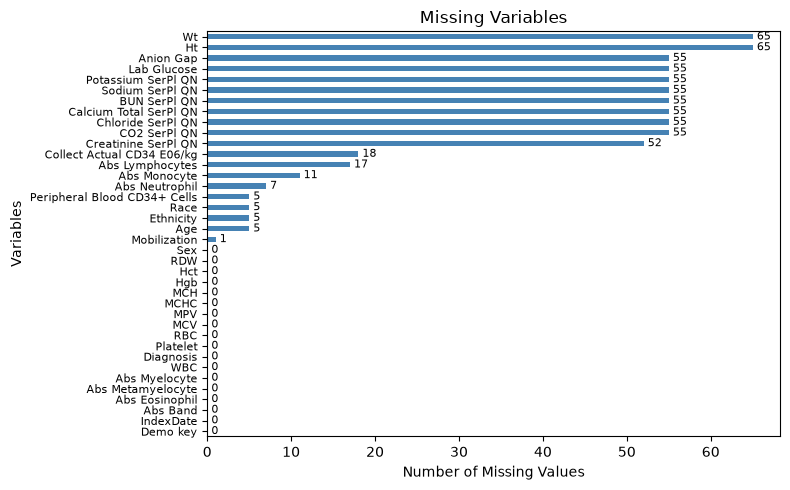

In [36]:
df1 = pd.read_excel("CDC_CleanedFile.xlsx")

NaN_co = df1.isna().sum()

exclude = []
duplicates = []
# Assign colors
colors = []

NaN_col = NaN_co.sort_values(ascending=True)
NaN_col = NaN_col.drop(index=exclude, errors="ignore")

for col in NaN_col.index:
    if col in duplicates:
        colors.append("orange")
    elif df[col].isna().mean() >= 0.30:
        colors.append("gray")
    else:
        colors.append("steelblue")

# Make the graph taller
ax = NaN_col.plot(kind="barh", color=colors, figsize=(8, 5))
ax.bar_label(ax.containers[0], padding=3, fontsize=8)

# Adjust label sizes
ax.tick_params(axis="y", labelsize=8)
ax.tick_params(axis="x", labelsize=10)

# Customize
plt.xlabel("Number of Missing Values")
plt.ylabel("Variables")
plt.title("Missing Variables")

# add threshold line
threshold = len(df) * .30

# Fix spacing
plt.tight_layout()
plt.savefig("cleanedgraph.png", dpi=300, bbox_inches="tight")
plt.show()

# Characteristic Table

In [ ]:
df.columns.unique()

In [ ]:
obs = ["Diagnosis"]

df["AG"] = pd.cut(df["Age"], bins=[0, 18, 40, 100], labels=["<18", "18-40", ">40"])

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)

df.groupby("AG", observed=False)[obs].value_counts()

In [ ]:
obs = ["Diagnosis"]

df1["AG"] = pd.cut(df1["Age"], bins=[0, 18, 40, 100], labels=["<18", "18-40", ">40"])

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)

df1.groupby("AG", observed=False)[obs].value_counts()


AG     Diagnosis               
<18    Neuroblastoma                39
       GCT                           9
       HD                            8
       Other                         5
       NHL                           3
       Other:  Please comment        3
       Allo MRD                      1
       CNS Tumor                     1
       ETMR                          1
       Medulloblastoma               1
       PNET                          1
       Retinoblastoma                1
       Rhabdomyosarcoma              1
       Wilm's Tumor                  1
       ATRT                          0
       Allo NMDP                     0
       Amyloidosis                   0
       B-Cell/CNS Lymphoma           0
       CNS Lymphoma                  0
       Choroid Plexus Carcinoma      0
       DLCBCL                        0
       MM                            0
       Mantle cell lymphoma          0
       Neuro Lymphoma                0
       Primary CNS Lymphoma     

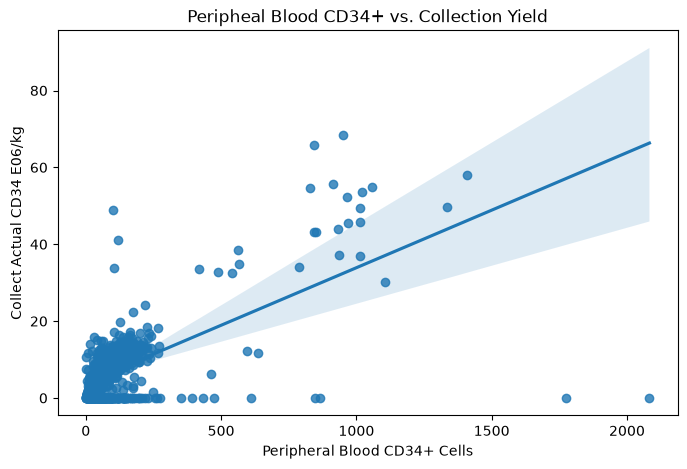

In [ ]:
# correlate Collected Actual CD34+ cells/kg with Peripheal Blood CD34+ (cells/microliter) to find outcome

x="Peripheral Blood CD34+ Cells"
y="Collect Actual CD34 E06/kg"

data = df1[[x,y]].dropna()

plt.figure(figsize=(8,5))
sns.regplot(data=data, x=x, y=y)

plt.title("Peripheal Blood CD34+ vs. Collection Yield")

plt.show()

In [ ]:
# find the microliter collection for mobilizer threshold

x="Peripheral Blood CD34+ Cells"
y="Collect Actual CD34 E06/kg"

data = df1[[x, y]].dropna()

# Calculate
slope, intercept = np.polyfit(data[x], data[y], 1)

target = 5

cd34_needed = (target - intercept) / slope

print(target)
print(cd34_needed)

5
35.21795018427151
